# Lab 19 — Boosting: AdaBoost, Gradient Boosting, XGBoost, and CatBoost

This lab gives you hands-on practice with four boosting algorithms on the
Breast Cancer dataset.  You will build baseline models, tune one algorithm,
select the best configuration, and interpret feature importance.

Work through each task in order.  The validation set is used for model
selection; the test set is used only for the final evaluation.


## Learning Outcomes

By the end of this lab you should be able to:

1. Load a dataset and perform a stratified train / validation / test split.
2. Implement AdaBoost, Gradient Boosting, XGBoost, and CatBoost classifiers.
3. Evaluate models using accuracy, precision, recall, and macro F1-score.
4. Conduct single-parameter experiments and interpret the results.
5. Select a final model using validation performance and report test results.
6. Extract and visualise built-in feature importances.


## Setup

Run the cell below once to install XGBoost and CatBoost if they are not already
present in your environment.


In [3]:
%pip -q install xgboost catboost


### Import libraries


In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import AdaBoostClassifier, GradientBoostingClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
)
from sklearn.base import clone
from xgboost import XGBClassifier
from catboost import CatBoostClassifier

print("scikit-learn version:", sklearn.__version__)
print("All libraries imported successfully.")


scikit-learn version: 1.6.1
All libraries imported successfully.


## Task 1 — Load and Inspect the Dataset

We use `load_breast_cancer`, a built-in scikit-learn binary classification
dataset.  All features are numerical.

**Target labels:** `0 = malignant`, `1 = benign`


In [5]:
dataset = load_breast_cancer()

# Put features and labels into convenient pandas structures
X = pd.DataFrame(dataset.data, columns=dataset.feature_names)
y = pd.Series(dataset.target, name="target")

print("Dataset description (first 1 000 characters):")
print(dataset.DESCR[:1000], "...")

print("\nFeature matrix shape:", X.shape)
print("Target shape:", y.shape)
print("Target names:", dict(enumerate(dataset.target_names)))

print("\nClass distribution:")
label_map = {i: name for i, name in enumerate(dataset.target_names)}
print(y.map(label_map).value_counts())

display(X.head())


Dataset description (first 1 000 characters):
.. _breast_cancer_dataset:

Breast cancer wisconsin (diagnostic) dataset
--------------------------------------------

**Data Set Characteristics:**

:Number of Instances: 569

:Number of Attributes: 30 numeric, predictive attributes and the class

:Attribute Information:
    - radius (mean of distances from center to points on the perimeter)
    - texture (standard deviation of gray-scale values)
    - perimeter
    - area
    - smoothness (local variation in radius lengths)
    - compactness (perimeter^2 / area - 1.0)
    - concavity (severity of concave portions of the contour)
    - concave points (number of concave portions of the contour)
    - symmetry
    - fractal dimension ("coastline approximation" - 1)

    The mean, standard error, and "worst" or largest (mean of the three
    worst/largest values) of these features were computed for each image,
    resulting in 30 features.  For instance, field 0 is Mean Radius, field
    10 i

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


In [6]:
# This cell runs assertion checks — no changes needed here.
# If the assertions fail, review how you built X and y above.

assert X.isna().sum().sum() == 0, "Unexpected missing values in features."
assert y.isna().sum() == 0, "Unexpected missing values in target."
assert set(y.unique()) == {0, 1}, "Expected binary labels 0 and 1."

print("No missing values found.")
print("Class labels:", sorted(y.unique()))


No missing values found.
Class labels: [np.int64(0), np.int64(1)]


### Create the Train–Test Split

We set aside 20 % of the data as a held-out test set right away.
This set will not be used again until Task 9.


In [8]:
# TODO: Split X and y into training and test sets.
# Use test_size=0.20, random_state=42, and stratify by y.
# Name the outputs: X_train, X_test, y_train, y_test
# Print the shapes and class distributions of both splits.

# YOUR CODE HERE

X_train, X_test, y_train, y_test = train_test_split(
    ...,
    ...,
    test_size=...,
    random_state=42,
    stratify=y,          # keeps the class ratio the same in both halves
)
print("Training set:", X_train.shape)
print("Test set:    ", X_test.shape)

print("\nTraining class distribution:")
print(y_train.value_counts().sort_index())

print("\nTest class distribution:")
print(y_test.value_counts().sort_index())


Training set: (455, 30)
Test set:     (114, 30)

Training class distribution:
target
0    170
1    285
Name: count, dtype: int64

Test class distribution:
target
0    42
1    72
Name: count, dtype: int64


**Questions**
1. Why do we use `stratify=y` when creating the train–test split?
2. Why must the test set remain completely separate during model selection?


## Task 2 — Create a Validation Set and Define Evaluation Metrics

We carve out a further 20 % of the training data as a validation set.
The test set remains untouched during all baseline comparisons and
hyperparameter experiments.


In [9]:
# TODO: Split X_train / y_train into a fitting set and a validation set.
# Use test_size=0.20, random_state=42, and stratify by y_train.
# Name the outputs: X_fit, X_val, y_fit, y_val
# Print the shapes of both splits.

# YOUR CODE HERE
X_fit, X_val, y_fit, y_val = train_test_split(
    ......,
    ......,
    test_size=...,
    random_state=42,
    stratify=y_train,
)

print("Model-fitting set:", X_fit.shape)
print("Validation set:   ", X_val.shape)


Model-fitting set: (364, 30)
Validation set:    (91, 30)


In [10]:
# TODO: Define a function called evaluate_model(y_true, y_pred)
# that returns a dict with keys:
#   "Accuracy", "Precision_Macro", "Recall_Macro", "F1_Macro"
# Use average="macro" and zero_division=0 for the sklearn metrics.

# YOUR CODE HERE
def evaluate_model(y_true, y_pred):
    """Return a dict of four common classification metrics."""
    return {
        "Accuracy":        .....,
        "Precision_Macro": ......,
        "Recall_Macro":    .......,
        "F1_Macro":        ......,
    }


## Task 3 — Implement AdaBoost

AdaBoost trains a sequence of weak learners and increases the weight of
observations that the previous learner got wrong.  A decision stump
(a tree with `max_depth=1`) is the standard choice for the base learner.

> **Note on the sklearn API**  
> `base_estimator` was renamed to `estimator` in scikit-learn 1.2 and the old
> name was removed in 1.4.  We use `estimator` throughout this lab.


In [11]:
# TODO: Create an AdaBoostClassifier with:
#   - estimator = DecisionTreeClassifier(max_depth=1, random_state=42)
#   - n_estimators = 100
#   - learning_rate = 0.5
#   - random_state = 42
#
# Fit the model on X_fit and y_fit.
# Predict on X_val and store predictions in y_pred_ada.
# Print the evaluation metrics and classification report.
# Add the trained model to a dict: baseline_models = {"AdaBoost": ada_model}

# YOUR CODE HERE
decision_stump = DecisionTreeClassifier(max_depth=1, random_state=42)

ada_model = .....

........fit(......, ......)

y_pred_ada = np.asarray(ada_model.predict(X_val)).reshape(-1)

print("AdaBoost — validation metrics:")
print(evaluate_model(y_val, y_pred_ada))

print("\nClassification report:")
print(classification_report(y_val, y_pred_ada, target_names=dataset.target_names, zero_division=0))

# Store for later comparison
baseline_models = {"AdaBoost": ada_model}

AdaBoost — validation metrics:
{'Accuracy': 0.9560439560439561, 'Precision_Macro': 0.9589512711864407, 'Recall_Macro': 0.947110423116615, 'F1_Macro': 0.952455590386625}

Classification report:
              precision    recall  f1-score   support

   malignant       0.97      0.91      0.94        34
      benign       0.95      0.98      0.97        57

    accuracy                           0.96        91
   macro avg       0.96      0.95      0.95        91
weighted avg       0.96      0.96      0.96        91



**Questions**
1. Why is a decision stump commonly used as the AdaBoost base learner?
2. How does AdaBoost respond to observations that were misclassified?
3. What could happen if the number of estimators becomes excessively large?


## Task 4 — Implement Gradient Boosting

Gradient Boosting builds an additive ensemble stage by stage.  Each new
learner fits the pseudo-residuals (negative gradients) of the current
ensemble, pushing the predictions in the right direction.


In [ ]:
# TODO: Create a GradientBoostingClassifier with:
#   - n_estimators = 100
#   - learning_rate = 0.1
#   - max_depth = 3
#   - random_state = 42
#
# Fit on X_fit / y_fit, predict on X_val, store predictions in y_pred_gb.
# Print metrics and classification report.
# Add to baseline_models: baseline_models["Gradient Boosting"] = gb_model

# YOUR CODE HERE
gb_model = .......(
    .....
)

..........fit(......, ......)

y_pred_gb = np.asarray(gb_model.predict(X_val)).reshape(-1)

print("Gradient Boosting — validation metrics:")
print(evaluate_model(y_val, y_pred_gb))

print("\nClassification report:")
print(classification_report(y_val, y_pred_gb, target_names=dataset.target_names, zero_division=0))

baseline_models["Gradient Boosting"] = gb_model


**Questions**
1. How does Gradient Boosting improve the ensemble at each stage?
2. What is the relationship between `learning_rate` and `n_estimators`?
3. How might increasing `max_depth` affect overfitting?


## Task 5 — Implement XGBoost

XGBoost is a highly optimised implementation of gradient boosting.  It adds
L1/L2 regularisation, column subsampling, and other techniques that often
improve generalisation compared with the scikit-learn baseline.


In [12]:
# TODO: Create an XGBClassifier with:
#   - n_estimators=100, learning_rate=0.1, max_depth=3
#   - subsample=0.8, colsample_bytree=0.8, reg_lambda=1.0
#   - objective="binary:logistic", eval_metric="logloss"
#   - random_state=42, n_jobs=-1, tree_method="hist"
#
# Fit on X_fit / y_fit, predict on X_val, store predictions in y_pred_xgb.
# Print metrics and classification report.
# Add to baseline_models: baseline_models["XGBoost"] = xgb_model

# YOUR CODE HERE
xgb_model = ......(
    ......    )

.....fit(...., ....)

y_pred_xgb = np.asarray(xgb_model.predict(X_val)).reshape(-1)

print("XGBoost — validation metrics:")
print(evaluate_model(y_val, y_pred_xgb))

print("\nClassification report:")
print(classification_report(y_val, y_pred_xgb, target_names=dataset.target_names, zero_division=0))

baseline_models["XGBoost"] = xgb_model


XGBoost — validation metrics:
{'Accuracy': 0.9560439560439561, 'Precision_Macro': 0.9530443756449949, 'Recall_Macro': 0.9530443756449949, 'F1_Macro': 0.9530443756449949}

Classification report:
              precision    recall  f1-score   support

   malignant       0.94      0.94      0.94        34
      benign       0.96      0.96      0.96        57

    accuracy                           0.96        91
   macro avg       0.95      0.95      0.95        91
weighted avg       0.96      0.96      0.96        91



**Questions**
1. What role does regularisation play in XGBoost?
2. What are `subsample` and `colsample_bytree` doing?
3. What does the `binary:logistic` objective produce as output?


## Task 6 — Implement CatBoost

CatBoost is a gradient-boosting library with built-in handling of categorical
features.  This dataset is fully numerical, so this task focuses on
classification performance rather than categorical encoding.


In [13]:
# TODO: Create a CatBoostClassifier with:
#   - iterations=100, learning_rate=0.1, depth=6
#   - loss_function="Logloss", random_seed=42
#   - verbose=False, thread_count=-1
#
# Fit on X_fit / y_fit, predict on X_val, store predictions in y_pred_cat.
# Print metrics and classification report.
# Add to baseline_models: baseline_models["CatBoost"] = cat_model

# YOUR CODE HERE
cat_model = ......(
    .......   # use all available CPU cores
)

......fit(....., .....)

y_pred_cat = np.asarray(cat_model.predict(X_val)).reshape(-1)

print("CatBoost — validation metrics:")
print(evaluate_model(y_val, y_pred_cat))

print("\nClassification report:")
print(classification_report(y_val, y_pred_cat, target_names=dataset.target_names, zero_division=0))

baseline_models["CatBoost"] = cat_model


CatBoost — validation metrics:
{'Accuracy': 0.967032967032967, 'Precision_Macro': 0.9676071055381401, 'Recall_Macro': 0.9618163054695562, 'F1_Macro': 0.9645684620376379}

Classification report:
              precision    recall  f1-score   support

   malignant       0.97      0.94      0.96        34
      benign       0.97      0.98      0.97        57

    accuracy                           0.97        91
   macro avg       0.97      0.96      0.96        91
weighted avg       0.97      0.97      0.97        91



**Questions**
1. What is CatBoost designed for, and why is it useful for categorical data?
2. Which parameter controls the number of boosting iterations in CatBoost?
3. Why is categorical-feature handling not demonstrated in this lab?


## Task 7 — Compare the Four Baseline Models

All four models are evaluated on the same validation observations using the
same metrics.  The configurations differ, so this is a practical comparison
of baselines rather than a fair algorithm-to-algorithm benchmark.


In [14]:
# TODO: Loop over baseline_models, predict on X_val for each model,
# call evaluate_model(), add the model name as "Model" key,
# collect results in a list, convert to a DataFrame called baseline_results_df,
# select columns ["Model","Accuracy","Precision_Macro","Recall_Macro","F1_Macro"],
# sort by F1_Macro descending, and display it.

# YOUR CODE HERE
baseline_results = []

for model_name, model in baseline_models.items():
    y_pred = np.asarray(model.predict(X_val)).reshape(-1)
    metrics = evaluate_model(y_val, y_pred)
    metrics["Model"] = model_name
    baseline_results.append(metrics)

baseline_results_df = pd.DataFrame(baseline_results)[
    ["Model", "Accuracy", "Precision_Macro", "Recall_Macro", "F1_Macro"]
].sort_values(by="F1_Macro", ascending=False).reset_index(drop=True)

display(baseline_results_df)


,Model,Accuracy,Precision_Macro,Recall_Macro,F1_Macro
0,CatBoost,0.967033,0.967607,0.961816,0.964568
1,XGBoost,0.956044,0.953044,0.953044,0.953044
2,AdaBoost,0.956044,0.958951,0.947110,0.952456


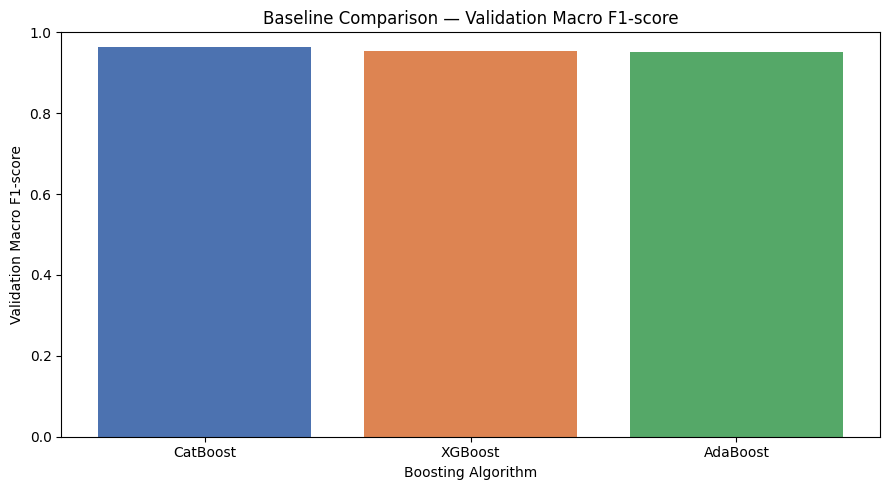

In [15]:
# TODO: Create a bar chart comparing the baseline models.
# x-axis: model names, y-axis: validation macro F1-score.
# Add appropriate axis labels and a title.

# YOUR CODE HERE
plt.figure(figsize=(9, 5))

plt.bar(
    baseline_results_df["Model"],
    baseline_results_df["F1_Macro"],
    color=["#4C72B0", "#DD8452", "#55A868", "#C44E52"],
)

plt.xlabel("Boosting Algorithm")
plt.ylabel("Validation Macro F1-score")
plt.title("Baseline Comparison — Validation Macro F1-score")
plt.ylim(0, 1)
plt.tight_layout()
plt.show()


**Questions**
1. Which baseline model achieved the highest validation macro F1-score?
2. Which model achieved the highest macro recall?
3. Did the model with the highest accuracy also achieve the highest macro F1-score?


## Task 8 — Hyperparameter Experiments with Gradient Boosting

We vary one parameter at a time while holding the others fixed.  These
experiments show individual parameter effects; they do not identify the
globally optimal combination.


In [16]:
# Initialise containers — no changes needed here.
hyperparameter_candidates = {}
hyperparameter_results = []


### Experiment 8.1 — Number of Estimators

Test `n_estimators` in `[25, 50, 100, 200]` with `learning_rate=0.1`
and `max_depth=3`.


In [17]:
# TODO: Loop over n_estimators in [25, 50, 100, 200].
# For each value, train a GradientBoostingClassifier (learning_rate=0.1,
# max_depth=3, random_state=42), predict on both X_fit and X_val,
# store the model in hyperparameter_candidates with key f"GB_n_estimators_{n}",
# and append a result dict to hyperparameter_results with keys:
#   "Experiment", "Setting", "Train_Accuracy", and all evaluate_model() keys.
# Display a DataFrame of the results at the end.

# YOUR CODE HERE
for n_estimators in [25, 50, 100, 200]:
    model = .........(
        n_estimators=n_estimators,
        learning_rate=0.1,
        max_depth=3,
        random_state=42,
    )
    ......fit(..., ....)

    train_pred = np.asarray(model.predict(X_fit)).reshape(-1)
    val_pred   = np.asarray(model.predict(X_val)).reshape(-1)

    model_name = f"GB_n_estimators_{n_estimators}"
    hyperparameter_candidates[model_name] = model

    hyperparameter_results.append({
        "Experiment":    "n_estimators",
        "Setting":       n_estimators,
        "Train_Accuracy": accuracy_score(y_fit, train_pred),
        **evaluate_model(y_val, val_pred),
    })

display(pd.DataFrame(hyperparameter_results))


,Experiment,Setting,Train_Accuracy,Accuracy,Precision_Macro,Recall_Macro,F1_Macro
0,n_estimators,25,0.997253,0.956044,0.953044,0.953044,0.953044
1,n_estimators,50,1.000000,0.956044,0.949242,0.958978,0.953571
2,n_estimators,100,1.000000,0.956044,0.949242,0.958978,0.953571
3,n_estimators,200,1.000000,0.967033,0.962500,0.967750,0.964987


**Questions**
1. Does increasing `n_estimators` always improve the validation macro F1-score?
2. What happens to training accuracy as the number of estimators increases?
3. Are there signs of diminishing returns beyond a certain value?


### Experiment 8.2 — Learning Rate

Test `learning_rate` in `[0.01, 0.05, 0.1, 0.2]` with `n_estimators=100`
and `max_depth=3`.


In [18]:
# TODO: Loop over learning_rate in [0.01, 0.05, 0.1, 0.2].
# Same structure as Experiment 8.1 but vary learning_rate (n_estimators=100,
# max_depth=3).  Store each model with key f"GB_learning_rate_{lr}".
# Display results.

# YOUR CODE HERE
for learning_rate in [0.01, 0.05, 0.1, 0.2]:
    model = GradientBoostingClassifier(
        n_estimators=100,
        learning_rate=learning_rate,
        max_depth=3,
        random_state=42,
    )
    model.fit(X_fit, y_fit)

    train_pred = np.asarray(model.predict(X_fit)).reshape(-1)
    val_pred   = np.asarray(model.predict(X_val)).reshape(-1)

    model_name = f"GB_learning_rate_{learning_rate}"
    hyperparameter_candidates[model_name] = model

    hyperparameter_results.append({
        "Experiment":    "learning_rate",
        "Setting":       learning_rate,
        "Train_Accuracy": accuracy_score(y_fit, train_pred),
        **evaluate_model(y_val, val_pred),
    })

display(pd.DataFrame(hyperparameter_results))

,Experiment,Setting,Train_Accuracy,Accuracy,Precision_Macro,Recall_Macro,F1_Macro
0,n_estimators,25.00,0.997253,0.956044,0.953044,0.953044,0.953044
1,n_estimators,50.00,1.000000,0.956044,0.949242,0.958978,0.953571
2,n_estimators,100.00,1.000000,0.956044,0.949242,0.958978,0.953571
3,n_estimators,200.00,1.000000,0.967033,0.962500,0.967750,0.964987
4,learning_rate,0.01,0.986264,0.945055,0.950538,0.932405,0.940171
5,learning_rate,0.05,1.000000,0.956044,0.949242,0.958978,0.953571
6,learning_rate,0.10,1.000000,0.956044,0.949242,0.958978,0.953571
7,learning_rate,0.20,1.000000,0.956044,0.953044,0.953044,0.953044


**Questions**
1. How does learning rate influence each tree's contribution to the ensemble?
2. Why might a smaller learning rate require more boosting iterations?
3. Which tested learning rate produced the highest validation macro F1-score?


### Experiment 8.3 — Tree Depth

Test `max_depth` in `[1, 2, 3, 5]` with `n_estimators=100` and
`learning_rate=0.1`.


In [19]:
# TODO: Loop over max_depth in [1, 2, 3, 5].
# Same structure as 8.1/8.2 but vary max_depth (n_estimators=100,
# learning_rate=0.1).  Store each model with key f"GB_max_depth_{d}".
# After the loop, create hyperparameter_results_df from hyperparameter_results,
# sort by F1_Macro descending, and display it.

# YOUR CODE HERE
for max_depth in [1, 2, 3, 5]:
    model = GradientBoostingClassifier(
        n_estimators=100,
        learning_rate=0.1,
        max_depth=max_depth,
        random_state=42,
    )
    model.fit(X_fit, y_fit)

    train_pred = np.asarray(model.predict(X_fit)).reshape(-1)
    val_pred   = np.asarray(model.predict(X_val)).reshape(-1)

    model_name = f"GB_max_depth_{max_depth}"
    hyperparameter_candidates[model_name] = model

    hyperparameter_results.append({
        "Experiment":    "max_depth",
        "Setting":       max_depth,
        "Train_Accuracy": accuracy_score(y_fit, train_pred),
        **evaluate_model(y_val, val_pred),
    })

hyperparameter_results_df = pd.DataFrame(hyperparameter_results)
display(
    hyperparameter_results_df.sort_values(by="F1_Macro", ascending=False)
                              .reset_index(drop=True)
)


,Experiment,Setting,Train_Accuracy,Accuracy,Precision_Macro,Recall_Macro,F1_Macro
0,n_estimators,200.00,1.000000,0.967033,0.962500,0.967750,0.964987
1,max_depth,5.00,1.000000,0.967033,0.967607,0.961816,0.964568
2,max_depth,1.00,0.991758,0.967033,0.967607,0.961816,0.964568
3,n_estimators,50.00,1.000000,0.956044,0.949242,0.958978,0.953571
4,max_depth,3.00,1.000000,0.956044,0.949242,0.958978,0.953571
5,n_estimators,100.00,1.000000,0.956044,0.949242,0.958978,0.953571
6,learning_rate,0.05,1.000000,0.956044,0.949242,0.958978,0.953571
7,learning_rate,0.10,1.000000,0.956044,0.949242,0.958978,0.953571
8,n_estimators,25.00,0.997253,0.956044,0.953044,0.953044,0.953044
9,learning_rate,0.20,1.000000,0.956044,0.953044,0.953044,0.953044


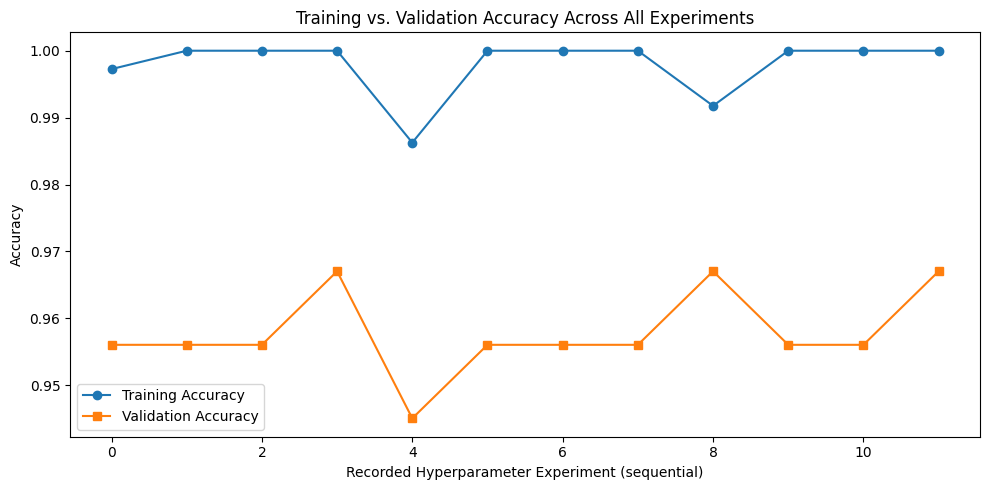

In [20]:
# TODO: Plot training accuracy vs validation accuracy across all hyperparameter
# experiments.  Use hyperparameter_results_df["Train_Accuracy"] and
# hyperparameter_results_df["Accuracy"].  Add labels, legend, and title.

# YOUR CODE HERE
plt.figure(figsize=(10, 5))

plt.plot(
    range(len(hyperparameter_results_df)),
    hyperparameter_results_df["Train_Accuracy"],
    marker="o",
    label="Training Accuracy",
)
plt.plot(
    range(len(hyperparameter_results_df)),
    hyperparameter_results_df["Accuracy"],
    marker="s",
    label="Validation Accuracy",
)

plt.xlabel("Recorded Hyperparameter Experiment (sequential)")
plt.ylabel("Accuracy")
plt.title("Training vs. Validation Accuracy Across All Experiments")
plt.legend()
plt.tight_layout()
plt.show()


**Interpretation**

- A large gap between training accuracy and validation accuracy suggests
  **overfitting**: the model memorised the training data.
- Similar training and validation accuracy suggests better **generalisation**,
  though both could also be low (underfitting).
- Always use **validation metrics** — not training accuracy — to choose
  between configurations.

**Questions**
1. How does tree depth affect model complexity?
2. Does the model with the highest training accuracy also perform best on
   the validation set?
3. Why is this single-parameter sweep not an exhaustive hyperparameter search?


## Task 9 — Select the Final Model and Evaluate the Test Set

We gather all candidates (baselines + hyperparameter variants), rank them
by validation macro F1-score, refit the winner on the full training set, and
then — for the first and only time — evaluate it on the held-out test set.


In [21]:
# TODO: Merge baseline_models and hyperparameter_candidates into a single dict
# called all_candidates.  Print how many candidates there are in total.

# YOUR CODE HERE
# Merge baseline models and hyperparameter-tuned models into one pool
all_candidates = {
    **baseline_models,
    **hyperparameter_candidates,
}

print("Total candidate configurations evaluated:", len(all_candidates))


Total candidate configurations evaluated: 15


In [22]:
# TODO: Loop over all_candidates, predict on X_val, evaluate each model,
# collect results in a DataFrame called candidate_results_df with columns
# ["Model","Accuracy","Precision_Macro","Recall_Macro","F1_Macro"],
# sorted by F1_Macro descending.  Display the DataFrame.

# YOUR CODE HERE
candidate_results = []

for model_name, model in all_candidates.items():
    y_pred = np.asarray(model.predict(X_val)).reshape(-1)
    metrics = evaluate_model(y_val, y_pred)
    metrics["Model"] = model_name
    candidate_results.append(metrics)

candidate_results_df = pd.DataFrame(candidate_results)[
    ["Model", "Accuracy", "Precision_Macro", "Recall_Macro", "F1_Macro"]
].sort_values(by="F1_Macro", ascending=False).reset_index(drop=True)

display(candidate_results_df)


,Model,Accuracy,Precision_Macro,Recall_Macro,F1_Macro
0,GB_n_estimators_200,0.967033,0.962500,0.967750,0.964987
1,CatBoost,0.967033,0.967607,0.961816,0.964568
2,GB_max_depth_5,0.967033,0.967607,0.961816,0.964568
3,GB_max_depth_1,0.967033,0.967607,0.961816,0.964568
4,GB_learning_rate_0.05,0.956044,0.949242,0.958978,0.953571
5,GB_n_estimators_100,0.956044,0.949242,0.958978,0.953571
6,GB_n_estimators_50,0.956044,0.949242,0.958978,0.953571
7,GB_max_depth_3,0.956044,0.949242,0.958978,0.953571
8,GB_learning_rate_0.1,0.956044,0.949242,0.958978,0.953571
9,XGBoost,0.956044,0.953044,0.953044,0.953044


In [23]:
# TODO: Extract the top-ranked model name and model object from
# candidate_results_df and all_candidates.
# Print the selected candidate name and its validation macro F1-score.

# YOUR CODE HERE
# Pick the top-ranked candidate
selected_model_name = candidate_results_df.iloc[0]["Model"]
selected_model      = all_candidates[selected_model_name]

print("Selected candidate:              ", selected_model_name)
print("Best validation macro F1-score:  ", round(candidate_results_df.iloc[0]["F1_Macro"], 4))


Selected candidate:               GB_n_estimators_200
Best validation macro F1-score:   0.965


In [24]:
# TODO: Clone the selected model, refit it on the full X_train / y_train,
# predict on X_test, evaluate using evaluate_model(), and print the test
# metrics and a classification report.

# YOUR CODE HERE
final_model = clone(selected_model)
final_model.fit(X_train, y_train)

y_pred_test = np.asarray(final_model.predict(X_test)).reshape(-1)
test_metrics = evaluate_model(y_test, y_pred_test)

print("Selected model:", selected_model_name)
print("\nFinal test metrics:")
for metric, value in test_metrics.items():
    print(f"  {metric}: {value:.4f}")

print("\nFinal classification report:")
print(classification_report(y_test, y_pred_test, target_names=dataset.target_names, zero_division=0))


Selected model: GB_n_estimators_200

Final test metrics:
  Accuracy: 0.9561
  Precision_Macro: 0.9605
  Recall_Macro: 0.9454
  F1_Macro: 0.9521

Final classification report:
              precision    recall  f1-score   support

   malignant       0.97      0.90      0.94        42
      benign       0.95      0.99      0.97        72

    accuracy                           0.96       114
   macro avg       0.96      0.95      0.95       114
weighted avg       0.96      0.96      0.96       114



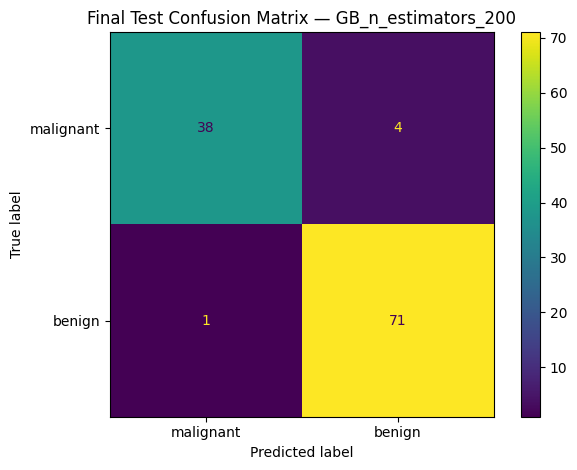

In [25]:
# TODO: Compute the confusion matrix for the test predictions and display it
# with ConfusionMatrixDisplay.  Add an informative title.

# YOUR CODE HERE
cm = confusion_matrix(y_test, y_pred_test)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=dataset.target_names,
)
disp.plot(values_format="d")
plt.title(f"Final Test Confusion Matrix — {selected_model_name}")
plt.tight_layout()
plt.show()


**Questions**
1. Which candidate was selected, and why?
2. Why do we refit the selected model on the full training set before testing?
3. Why should we not use the test results to pick a different model?
4. What types of classification errors does the confusion matrix reveal?

**Interpretation:** The selected model is the best among the candidates
evaluated under the given validation criterion.  It is not necessarily the
globally optimal model or the best possible configuration of all four algorithms.


## Task 10 — Analyse Feature Importance

Built-in feature importances are computed from the fitted `final_model`.
They are model-specific and should not be interpreted as causal influence.


In [26]:
# TODO: Extract final_model.feature_importances_, pair each importance with
# its feature name from X_train.columns, build a DataFrame called
# feature_importance_df, sort by Importance descending, and display the
# top 15 rows.

# YOUR CODE HERE
importances   = final_model.feature_importances_
feature_names = list(X_train.columns)

feature_importance_df = pd.DataFrame({
    "Feature":    feature_names,
    "Importance": importances,
}).sort_values(by="Importance", ascending=False).reset_index(drop=True)

display(feature_importance_df.head(15))


,Feature,Importance
0,worst radius,0.435471
1,worst perimeter,0.271465
2,worst concave points,0.106543
3,worst texture,0.052636
4,mean concave points,0.030458
5,texture error,0.026926
6,worst area,0.022316
7,worst concavity,0.010820
8,worst smoothness,0.010708
9,area error,0.005350


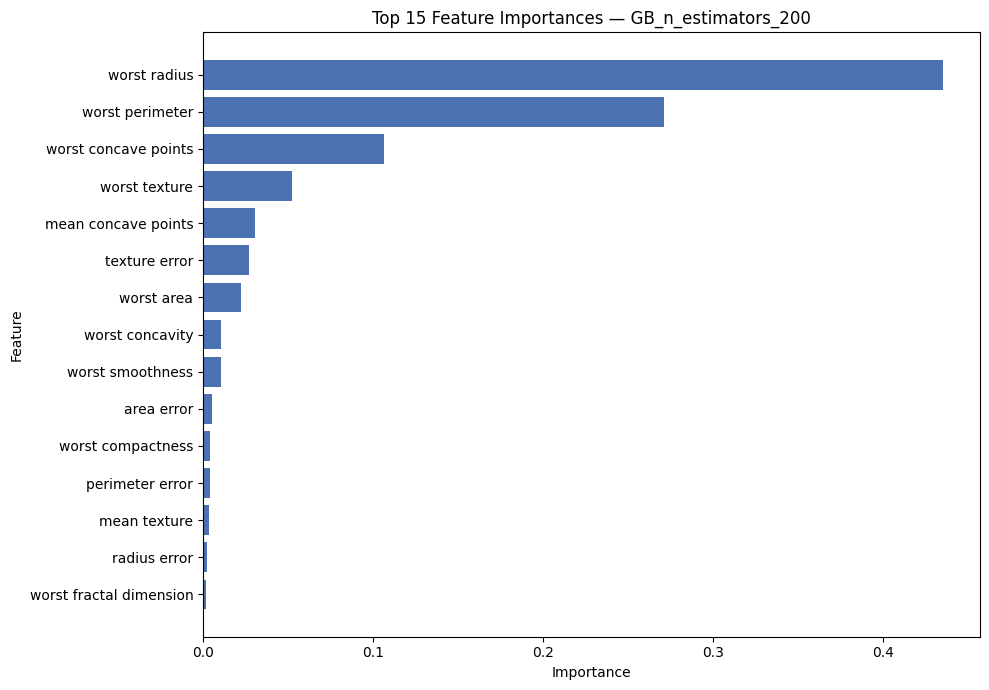

In [27]:
# TODO: Create a horizontal bar chart of the top 15 features.
# Sort ascending so the most important feature appears at the top.
# Add axis labels and a title that includes the selected model name.

# YOUR CODE HERE
top_features = feature_importance_df.head(15).sort_values(by="Importance", ascending=True)

plt.figure(figsize=(10, 7))
plt.barh(top_features["Feature"], top_features["Importance"], color="#4C72B0")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title(f"Top 15 Feature Importances — {selected_model_name}")
plt.tight_layout()
plt.show()


**Questions**
1. Which feature has the highest model-reported importance?
2. Does a highly ranked feature necessarily *cause* the target outcome?
3. What additional analysis could you use to assess the robustness of these
   feature-importance rankings?


## Task 11 — Conclusion and Submission

Complete the written summary below (replace the placeholder text).

1. **Algorithms implemented:** _(list all four)_
2. **Baseline validation macro F1-scores:** _(fill in from Task 7)_
3. **Best Gradient Boosting hyperparameter setting:** _(fill in from Task 8)_
4. **Selected candidate and selection criterion:** _(fill in from Task 9)_
5. **Final test accuracy and macro F1-score:** _(fill in from Task 9)_
6. **Most important feature:** _(fill in from Task 10)_
7. **One limitation of this study:** _(your own observation)_

---

### Submission Checklist

- [ ] Dataset inspection and train–test split outputs
- [ ] Implementations of all four boosting algorithms
- [ ] Baseline comparison table and bar chart
- [ ] Hyperparameter experiment results (all three sub-tasks)
- [ ] Training-versus-validation accuracy plot
- [ ] Final candidate-selection results table
- [ ] Test classification report and confusion matrix
- [ ] Feature-importance table and horizontal bar chart
- [ ] Written answers to every set of questions

---

### Methodological Note

This lab compares baseline configurations and tunes only Gradient Boosting.
The results support comparisons among the evaluated candidates, not a
definitive ranking of the four algorithms under fully optimised settings.
The test set remains reserved for estimating the selected model's
generalisation performance.
